# Semana 8 · Implementación y comparación de algoritmos de clasificación
**CADI Introducción a Machine Learning · Universidad de Cundinamarca**

**Caso:** Breast Cancer Wisconsin Diagnostic (Scikit-learn) · **Algoritmos:** Decision Tree, Random Forest, SVM, K-NN, Naive Bayes

> ⚠️ Uso exclusivamente académico. Los resultados no constituyen una herramienta clínica ni deben usarse para decisiones médicas.

**Autor:** _(escribe tu nombre aquí)_

## 1. Preparación del caso y los datos (Ejercicio 1)

In [1]:
# Librerías y carga del dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
X = data.data.copy()

# En Scikit-learn target 0 = maligno y 1 = benigno; se invierte para que 1 = maligno (clase positiva)
y = (data.target == 0).astype(int)

print("Dimensiones de X (filas, columnas):", X.shape)
print("\nDistribución de la variable objetivo:")
print(y.value_counts())
print("\nProporción (%):")
print((y.value_counts(normalize=True) * 100).round(2))
print("\nValores nulos en X:", X.isna().sum().sum())

Dimensiones de X (filas, columnas): (569, 30)

Distribución de la variable objetivo:
target
0    357
1    212
Name: count, dtype: int64

Proporción (%):
target
0    62.74
1    37.26
Name: proportion, dtype: float64

Valores nulos en X: 0


**💬 ¿Cuántas observaciones y variables contiene el conjunto de datos?**
Contiene **569 observaciones** (muestras) y **30 variables** numéricas continuas (media, error estándar y valor "peor" de 10 características del núcleo celular: radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal). No hay valores nulos.

**💬 ¿La variable objetivo está balanceada?**
Está **moderadamente desbalanceada**: 357 casos benignos (62.7 %) y 212 malignos (37.3 %). No es un desbalance extremo, pero la clase maligna (la de interés) es minoritaria; por eso la Accuracy sola puede ser engañosa (un modelo que dijera siempre "benigno" tendría ~62.7 % de Accuracy sin detectar ningún maligno).

**💬 ¿Por qué es importante definir con claridad qué representa la clase positiva?**
Porque Precision, Recall y F1 se calculan **respecto a la clase positiva**, y la matriz de confusión se interpreta a partir de ella (FP, FN). Aquí 1 = maligno, así que un *falso negativo* es un caso maligno no detectado (error grave) y un *falso positivo* es un benigno marcado como maligno. Si la clase positiva se invirtiera, las métricas significarían otra cosa. (En el dataset original de Scikit-learn la clase 0 es la maligna, por eso se invierte.)

### División entrenamiento / prueba

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(X_train.shape, X_test.shape)
print("\nProporción maligno en train:", round(y_train.mean(), 4))
print("Proporción maligno en test :", round(y_test.mean(), 4))
print("Malignos en test:", y_test.sum(), "| Benignos en test:", (y_test == 0).sum())

(455, 30) (114, 30)

Proporción maligno en train: 0.3736
Proporción maligno en test : 0.3684
Malignos en test: 42 | Benignos en test: 72


**💬 ¿Qué función cumple `stratify=y`?**
Mantiene en entrenamiento y prueba **la misma proporción de clases** que tiene el dataset completo (≈37 % malignos en ambos). Sin estratificar, el azar podría dejar el conjunto de prueba con muy pocos casos malignos y las métricas serían poco confiables. Esta misma división (`random_state=42`) se usa para los cinco modelos.

### Función común de evaluación

In [3]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

matrices = {}   # se guardan las matrices de confusión para graficarlas después

def evaluar_modelo(nombre, modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)
    cm = confusion_matrix(y_eval, pred)
    matrices[nombre] = cm
    resultados = {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred),
        'Recall': recall_score(y_eval, pred),
        'F1': f1_score(y_eval, pred)
    }
    tn, fp, fn, tp = cm.ravel()
    print(nombre)
    print("Matriz de confusión [[TN FP], [FN TP]]:")
    print(cm)
    print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")
    print({k: round(v, 4) for k, v in resultados.items() if k != 'Modelo'})
    return resultados

lista_resultados = []   # aquí se acumulan los resultados de cada modelo

## 2. Decision Tree (Ejercicio 2)

In [4]:
from sklearn.tree import DecisionTreeClassifier

modelo_dt = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_dt.fit(X_train, y_train)
lista_resultados.append(evaluar_modelo('Decision Tree', modelo_dt, X_test, y_test))

Decision Tree
Matriz de confusión [[TN FP], [FN TP]]:
[[70  2]
 [ 8 34]]
TN=70 | FP=2 | FN=8 | TP=34
{'Accuracy': 0.9123, 'Precision': 0.9444, 'Recall': 0.8095, 'F1': 0.8718}


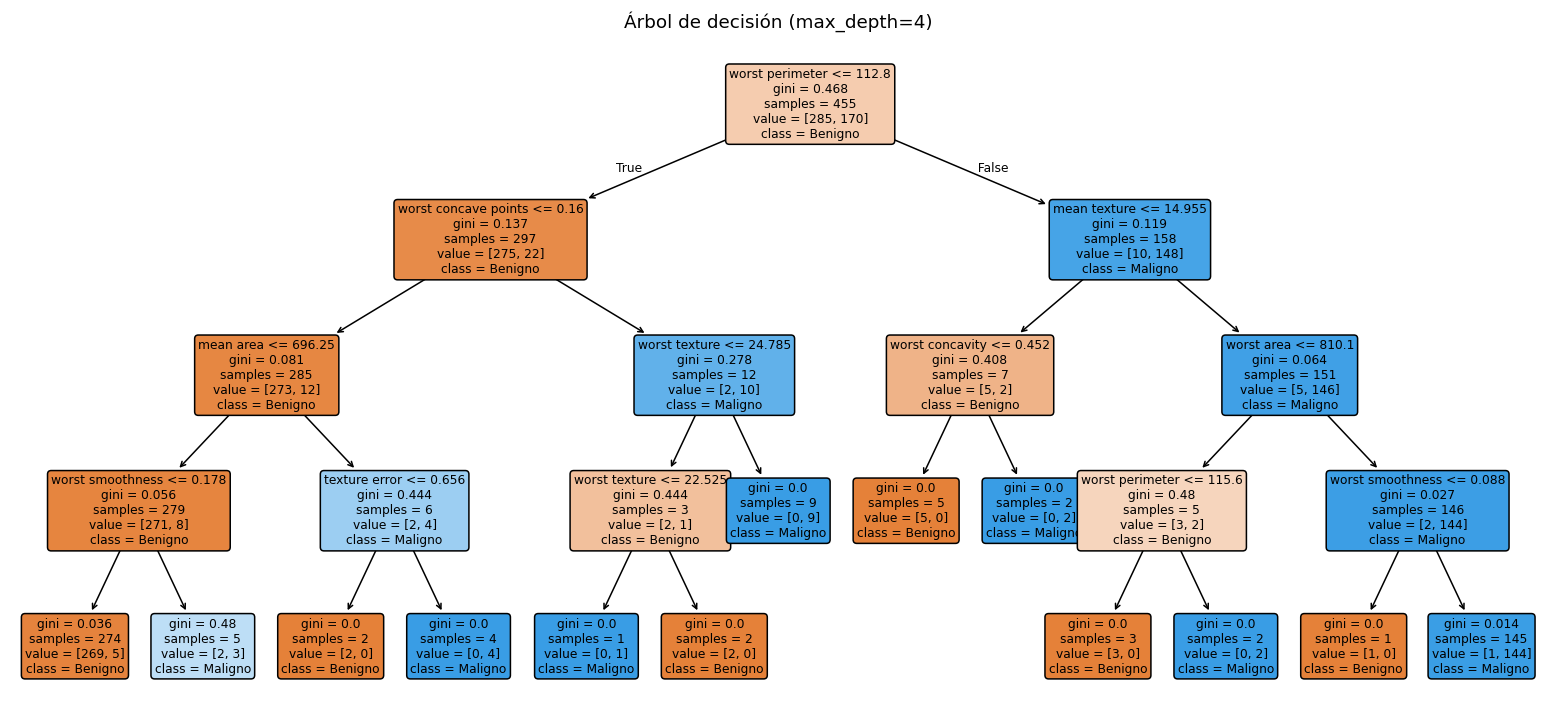

In [5]:
# Visualización del árbol (interpretabilidad)
from sklearn.tree import plot_tree
plt.figure(figsize=(18, 8))
plot_tree(modelo_dt, feature_names=X.columns, class_names=['Benigno', 'Maligno'],
          filled=True, rounded=True, fontsize=8)
plt.title("Árbol de decisión (max_depth=4)")
plt.show()

**💬 ¿Qué ventaja tiene limitar la profundidad del árbol?**
Un árbol sin límite crece hasta memorizar el entrenamiento (**sobreajuste**) y se vuelve enorme e ilegible. Con `max_depth=4` el modelo generaliza mejor, es más estable y **se puede leer completo**: cada camino es una regla del tipo "si el peor perímetro ≤ X y ... entonces maligno".

**💬 ¿Qué errores observas en la matriz de confusión?**
TN=70, FP=2, FN=8, TP=34. Casi todos los errores son **falsos negativos (8 casos malignos no detectados)**; solo hay 2 falsos positivos. Es el peor resultado en Recall (0.8095) entre los cinco modelos, justo en la métrica más crítica para este problema.

## 3. Random Forest (Ejercicio 3)

In [6]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)
lista_resultados.append(evaluar_modelo('Random Forest', modelo_rf, X_test, y_test))

Random Forest
Matriz de confusión [[TN FP], [FN TP]]:
[[72  0]
 [ 3 39]]
TN=72 | FP=0 | FN=3 | TP=39
{'Accuracy': 0.9737, 'Precision': 1.0, 'Recall': 0.9286, 'F1': 0.963}


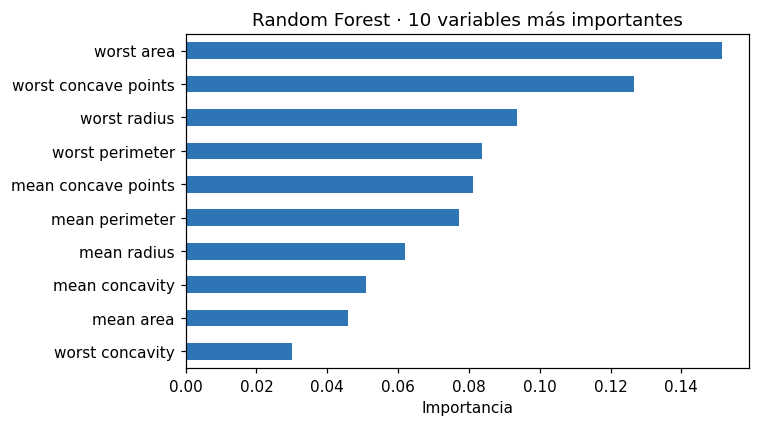

In [7]:
# Importancia de variables (10 principales)
imp = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind='barh', figsize=(7, 4), color='#2E75B6')
plt.title("Random Forest · 10 variables más importantes")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

**💬 ¿Qué cambia al pasar de un árbol individual a un conjunto de árboles?**
Random Forest entrena 100 árboles, cada uno con una muestra aleatoria (bootstrap) de las filas y un subconjunto aleatorio de variables en cada división, y combina sus predicciones por votación. Esto **reduce la varianza** y el sobreajuste de un árbol aislado, a cambio de perder la lectura directa de reglas (se pierde parte de la interpretabilidad; se compensa con la importancia de variables).

**💬 ¿Mejora alguna métrica? ¿Cuál y cuánto?**
Sí, **todas**: Accuracy 0.9123 → 0.9737 (+6.1 puntos), Precision 0.9444 → 1.0000 (+5.6), Recall 0.8095 → 0.9286 (+11.9) y F1 0.8718 → 0.9630 (+9.1). Los falsos negativos bajan de 8 a 3 y los falsos positivos de 2 a 0.

## 4. Support Vector Machine (Ejercicio 4)

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# El escalador se ajusta SOLO con X_train dentro del pipeline (evita fuga de datos)
modelo_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale')
)
modelo_svm.fit(X_train, y_train)
lista_resultados.append(evaluar_modelo('SVM', modelo_svm, X_test, y_test))

SVM
Matriz de confusión [[TN FP], [FN TP]]:
[[72  0]
 [ 3 39]]
TN=72 | FP=0 | FN=3 | TP=39
{'Accuracy': 0.9737, 'Precision': 1.0, 'Recall': 0.9286, 'F1': 0.963}


**💬 ¿Por qué en este modelo usamos `StandardScaler`?**
El kernel RBF de SVM depende de **distancias** entre puntos. Las variables de este dataset tienen escalas muy distintas (el área llega a ~2500 mientras la suavidad ronda 0.1), así que sin escalar el área dominaría el cálculo y las demás variables casi no influirían. `StandardScaler` deja todas con media 0 y desviación 1. Dentro del `Pipeline`, el escalador aprende sus parámetros solo con el entrenamiento y los aplica al conjunto de prueba, evitando fuga de información.

**💬 ¿Qué resultado obtiene SVM frente a los modelos basados en árboles?**
SVM obtiene **exactamente las mismas métricas que Random Forest** (Accuracy 0.9737, Precision 1.0, Recall 0.9286, F1 0.9630; FN=3, FP=0) y supera claramente al Decision Tree (Accuracy 0.9123, Recall 0.8095).

## 5. K-Nearest Neighbors (Ejercicio 5)

In [9]:
from sklearn.neighbors import KNeighborsClassifier

modelo_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
modelo_knn.fit(X_train, y_train)
lista_resultados.append(evaluar_modelo('K-NN', modelo_knn, X_test, y_test))

K-NN
Matriz de confusión [[TN FP], [FN TP]]:
[[71  1]
 [ 4 38]]
TN=71 | FP=1 | FN=4 | TP=38
{'Accuracy': 0.9561, 'Precision': 0.9744, 'Recall': 0.9048, 'F1': 0.9383}


**💬 ¿Qué representa k=5?**
Es el número de **vecinos más cercanos** que se consultan para clasificar una muestra nueva: el modelo busca las 5 muestras de entrenamiento más próximas y asigna la clase mayoritaria entre ellas. Un k pequeño es más sensible al ruido; uno grande suaviza la frontera pero puede ignorar patrones locales. K-NN no "aprende" parámetros: guarda los datos y calcula distancias al predecir.

**💬 ¿Por qué el escalamiento es especialmente importante cuando se calculan distancias?**
Porque la distancia euclidiana suma diferencias al cuadrado de todas las variables: las de mayor magnitud (área, perímetro) **dominarían** la distancia y las de menor magnitud (suavidad, simetría) serían irrelevantes aunque fueran informativas. Al estandarizar, todas contribuyen en igualdad de condiciones.

## 6. Naive Bayes (Ejercicio 6)

In [10]:
from sklearn.naive_bayes import GaussianNB

# Sin escalamiento, según la guía (GaussianNB estima media y varianza por variable y clase)
modelo_nb = GaussianNB()
modelo_nb.fit(X_train, y_train)
lista_resultados.append(evaluar_modelo('Naive Bayes', modelo_nb, X_test, y_test))

Naive Bayes
Matriz de confusión [[TN FP], [FN TP]]:
[[72  0]
 [ 7 35]]
TN=72 | FP=0 | FN=7 | TP=35
{'Accuracy': 0.9386, 'Precision': 1.0, 'Recall': 0.8333, 'F1': 0.9091}


**💬 ¿Qué supuesto simplificador utiliza Naive Bayes?**
Supone que las variables son **condicionalmente independientes** dadas la clase (y, en GaussianNB, que cada una sigue una distribución normal dentro de cada clase). En este dataset eso no se cumple: radio, perímetro y área están casi perfectamente correlacionados, de modo que el modelo "cuenta la misma información varias veces".

**💬 ¿En qué métricas se comporta mejor o peor que los otros clasificadores?**
**Mejor:** Precision = 1.0 (0 falsos positivos), igual que RF y SVM, y supera al Decision Tree en Accuracy y F1. **Peor:** Recall = 0.8333 con 7 falsos negativos, solo mejor que el Decision Tree y por debajo de K-NN, RF y SVM. Su Accuracy (0.9386) y F1 (0.9091) quedan en el penúltimo lugar. Es el modelo más "conservador": no se equivoca al marcar malignos, pero deja pasar bastantes.

## 7. Comparación y toma de decisión (Ejercicio 7)

In [11]:
resultados_df = pd.DataFrame(lista_resultados).set_index('Modelo')

# Falsos negativos y falsos positivos por modelo
resultados_df['FN'] = [matrices[m][1, 0] for m in resultados_df.index]
resultados_df['FP'] = [matrices[m][0, 1] for m in resultados_df.index]

print("Tabla comparativa (conjunto de prueba, n=114):")
resultados_df.round(4)

Tabla comparativa (conjunto de prueba, n=114):


,Accuracy,Precision,Recall,F1,FN,FP
Modelo,,,,,,
Decision Tree,0.9123,0.9444,0.8095,0.8718,8,2
Random Forest,0.9737,1.0000,0.9286,0.9630,3,0
SVM,0.9737,1.0000,0.9286,0.9630,3,0
K-NN,0.9561,0.9744,0.9048,0.9383,4,1
Naive Bayes,0.9386,1.0000,0.8333,0.9091,7,0


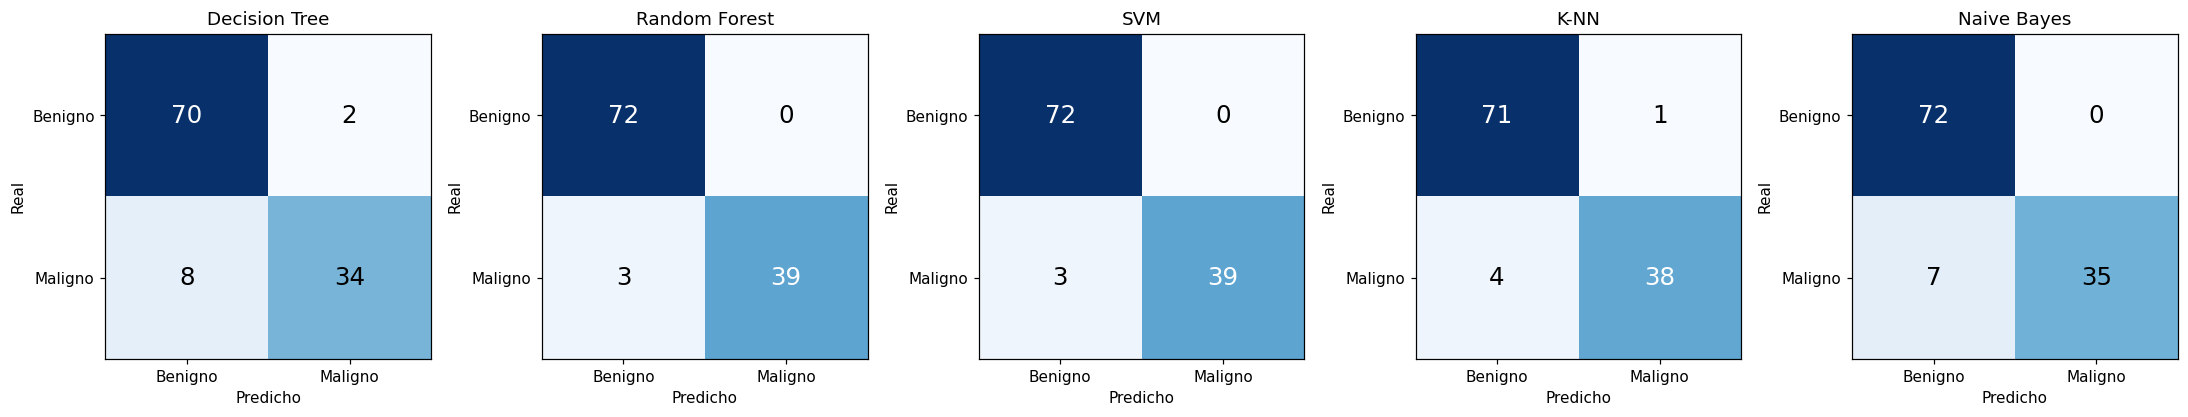

In [12]:
# Matrices de confusión de los cinco modelos
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (nombre, cm) in zip(axes, matrices.items()):
    ax.imshow(cm, cmap='Blues')
    ax.set_title(nombre)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Benigno', 'Maligno']); ax.set_yticklabels(['Benigno', 'Maligno'])
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=16,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

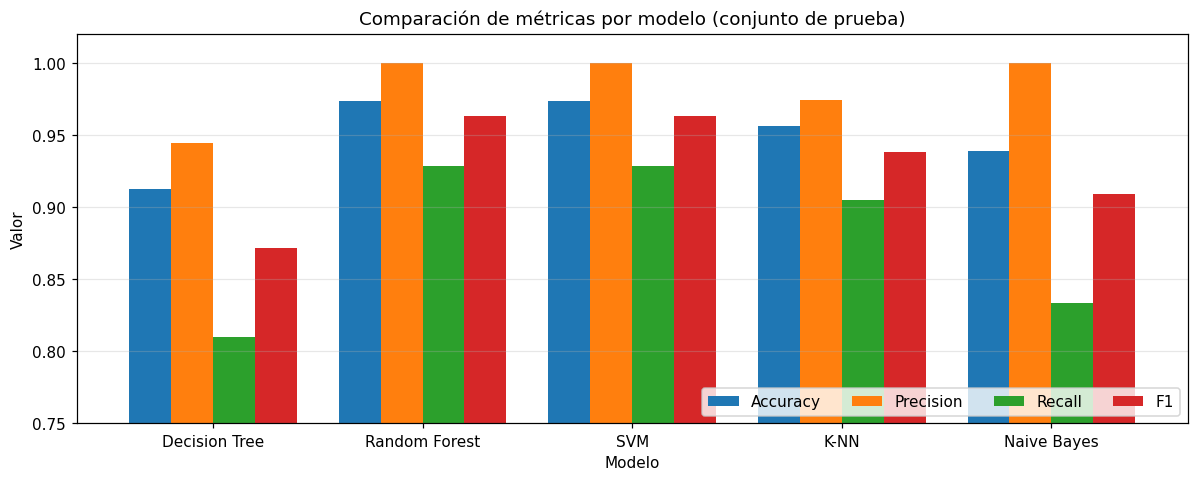

In [13]:
# Comparación gráfica de métricas
resultados_df[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(11, 4.5), width=0.8)
plt.ylim(0.75, 1.02)
plt.title("Comparación de métricas por modelo (conjunto de prueba)")
plt.ylabel("Valor")
plt.xticks(rotation=0)
plt.legend(loc='lower right', ncol=4)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Tabla comparativa con interpretación

| Modelo | Accuracy | Precision | Recall | F1 | FN | FP | Observación |
|---|---|---|---|---|---|---|---|
| Decision Tree | 0.9123 | 0.9444 | 0.8095 | 0.8718 | 8 | 2 | El más interpretable, pero el peor: deja pasar 8 de 42 malignos. |
| Random Forest | 0.9737 | 1.0000 | 0.9286 | 0.9630 | 3 | 0 | Empata en el mejor desempeño; no requiere escalamiento y da importancia de variables. |
| SVM | 0.9737 | 1.0000 | 0.9286 | 0.9630 | 3 | 0 | Empata en el mejor desempeño; requiere escalamiento y es el más difícil de explicar. |
| K-NN | 0.9561 | 0.9744 | 0.9048 | 0.9383 | 4 | 1 | Muy buen resultado y sencillo de entender, pero un caso peor que RF/SVM; sensible al escalamiento. |
| Naive Bayes | 0.9386 | 1.0000 | 0.8333 | 0.9091 | 7 | 0 | Sin falsos positivos, pero 7 falsos negativos; el supuesto de independencia no se cumple bien. |

### Preguntas de análisis

**7. ¿Qué modelo obtuvo la mayor Accuracy?**
**Random Forest y SVM empatan** con 0.9737 (111 de 114 aciertos).

**8. ¿Qué modelo obtuvo el mayor Recall para la clase maligna?**
También **Random Forest y SVM** con 0.9286 (39 de 42 malignos detectados). Le sigue K-NN (0.9048), luego Naive Bayes (0.8333) y por último el Decision Tree (0.8095).

**9. ¿Qué modelo produjo menos falsos negativos?**
**Random Forest y SVM**, con 3 falsos negativos cada uno (K-NN: 4, Naive Bayes: 7, Decision Tree: 8).

**10. ¿Coincide el modelo con mayor Accuracy con el que seleccionarías?**
Parcialmente: el mayor Accuracy lo comparten RF y SVM, y el empate también aparece en Precision, Recall y F1, así que las métricas no los separan. Entre ellos elegiría **Random Forest** por criterios adicionales: no necesita escalamiento, ofrece importancia de variables que permite explicar en qué se basa y es más robusto frente a datos nuevos sin ajustes. Además, Naive Bayes tiene Precision perfecta pero un Recall bajo: un ejemplo claro de por qué no basta mirar una sola métrica.

**11. Si el costo de no detectar un caso maligno fuera especialmente alto, ¿qué métrica priorizaría?**
El **Recall** de la clase maligna (sensibilidad), porque mide qué proporción de los casos malignos reales se detectan y está directamente ligada a los falsos negativos. Aceptaría más falsos positivos (que se resuelven con una prueba confirmatoria) a cambio de perder menos casos malignos. En ese escenario el Decision Tree (8 FN) y Naive Bayes (7 FN) quedarían descartados. Para subir aún más el Recall se podría ajustar el umbral de decisión con `predict_proba`.

**12. ¿Cuál es más sencillo de explicar a una persona no técnica?**
El **Decision Tree**: se explica como un diagrama de preguntas de sí/no. K-NN también es intuitivo ("se parece a sus 5 casos más cercanos"). SVM es el más abstracto.

**13. ¿Qué diferencias observaste entre los algoritmos que requieren escalamiento y los que no?**
SVM y K-NN calculan distancias y por eso exigen estandarizar; con escalamiento obtuvieron resultados altos (SVM 0.9737, K-NN 0.9561). Los árboles y Random Forest dividen por umbrales de una sola variable, por lo que no se ven afectados por la escala. Naive Bayes modela cada variable por separado con su propia media y varianza, por lo que tampoco la necesita. Escalar es un paso de preprocesamiento que depende del algoritmo, y debe hacerse dentro del `Pipeline` para evitar fuga de datos.

**14. Modelo final**
**Random Forest.** Justificación: (1) Recall = 0.9286 con solo 3 falsos negativos, el mejor junto con SVM y 5 FN menos que el Decision Tree; (2) Precision = 1.0 y F1 = 0.9630, sin falsos positivos; (3) contexto: en un problema diagnóstico el error más costoso es no detectar un maligno, y Random Forest además permite mostrar qué variables (p. ej. peor perímetro, peor radio, peor área) pesan en la decisión, lo que facilita la confianza de quien la usa. **Limitación:** el conjunto de prueba tiene solo 42 malignos, así que la diferencia de 1 caso entre modelos (p. ej. RF vs K-NN) no es estadísticamente concluyente, y el resultado es académico, no clínico.

## 8. Verificación adicional (opcional): validación cruzada sobre el entrenamiento
Sin tocar el conjunto de prueba, se confirma que el orden de los modelos no depende de una sola partición.

In [14]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelos = {'Decision Tree': modelo_dt, 'Random Forest': modelo_rf, 'SVM': modelo_svm,
           'K-NN': modelo_knn, 'Naive Bayes': modelo_nb}
filas = []
for nombre, m in modelos.items():
    rec = cross_val_score(m, X_train, y_train, cv=cv, scoring='recall')
    f1 = cross_val_score(m, X_train, y_train, cv=cv, scoring='f1')
    filas.append({'Modelo': nombre, 'Recall CV (media)': rec.mean(), 'Recall CV (std)': rec.std(),
                  'F1 CV (media)': f1.mean()})
pd.DataFrame(filas).set_index('Modelo').round(4)

,Recall CV (media),Recall CV (std),F1 CV (media)
Modelo,,,
Decision Tree,0.8647,0.0780,0.8897
Random Forest,0.9412,0.0416,0.9519
SVM,0.9471,0.0343,0.9610
K-NN,0.9176,0.0343,0.9510
Naive Bayes,0.9000,0.0546,0.9185


**Interpretación de la validación cruzada:** SVM (Recall 0.947, F1 0.961) y Random Forest (Recall 0.941, F1 0.952) quedan prácticamente empatados; la diferencia es menor que la desviación estándar entre particiones (≈0.03–0.04). El Decision Tree sigue siendo el más débil (Recall 0.865) y K-NN y Naive Bayes quedan en posiciones intermedias. Esto confirma que **RF y SVM son las mejores opciones** y que elegir entre ambos depende de criterios adicionales (interpretabilidad, preprocesamiento), no de las métricas.

## 9. Conclusiones
- Con la misma división (80/20, `random_state=42`, estratificada), **Random Forest y SVM fueron los mejores** (Accuracy 0.9737, Recall 0.9286, Precision 1.0); K-NN quedó cerca (0.9561); Naive Bayes y el Decision Tree fueron los más débiles en Recall (0.8333 y 0.8095).
- La **Accuracy no basta**: Naive Bayes tiene Precision perfecta pero deja pasar 7 malignos. En este contexto importa el **Recall** y la matriz de confusión.
- Hay un compromiso **interpretabilidad vs. desempeño**: el árbol es el más explicable pero el menos preciso; Random Forest recupera casi toda la explicabilidad mediante la importancia de variables.
- El escalamiento es obligatorio para SVM y K-NN, y no necesario para árboles, Random Forest y Naive Bayes.
- **Modelo final: Random Forest.** Limitación: conjunto de prueba pequeño (114 muestras, 42 malignas); el ejercicio es solo académico.

## 10. Referencias
- Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). *Nuclear feature extraction for breast tumor diagnosis*. IS&T/SPIE International Symposium on Electronic Imaging.
- Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1995). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830. https://scikit-learn.org